In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7043
Columns: 21


In [9]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

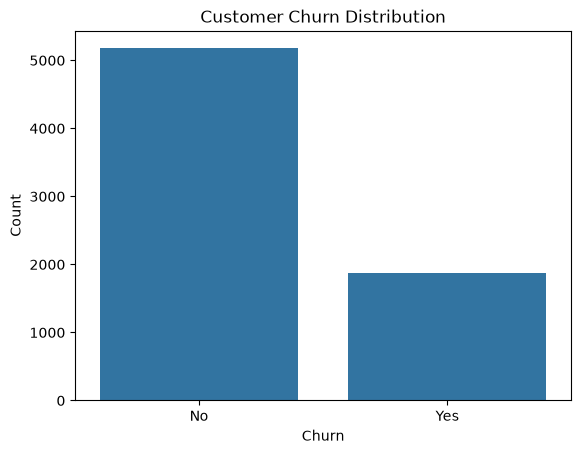

In [10]:
sns.countplot(x='Churn', data=df)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

In [11]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [12]:
categorical_cols = df.select_dtypes(include='object').columns
categorical_cols

C:\Users\Admin\AppData\Local\Temp\ipykernel_12956\2674823712.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns


Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='str')

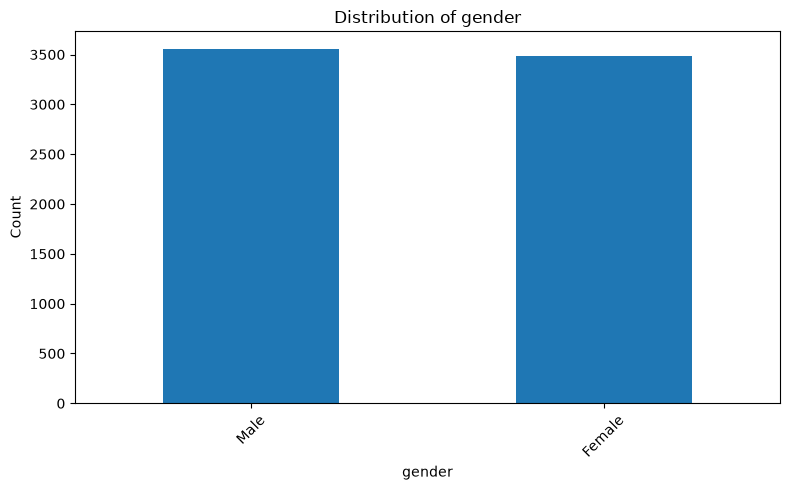

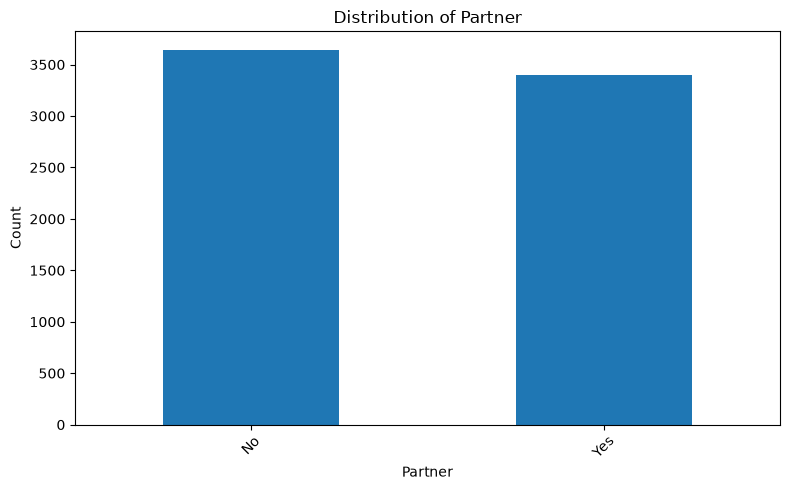

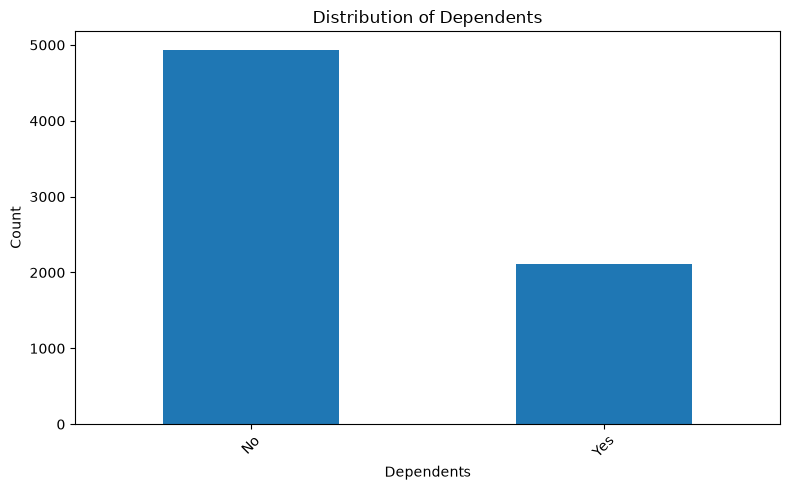

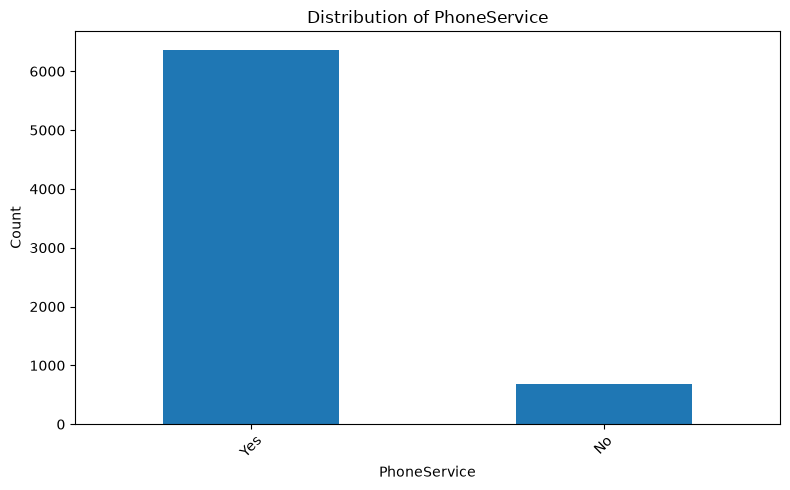

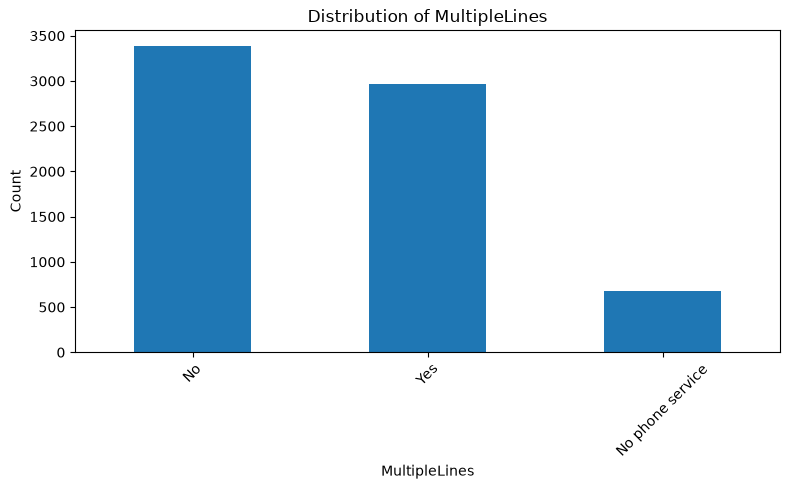

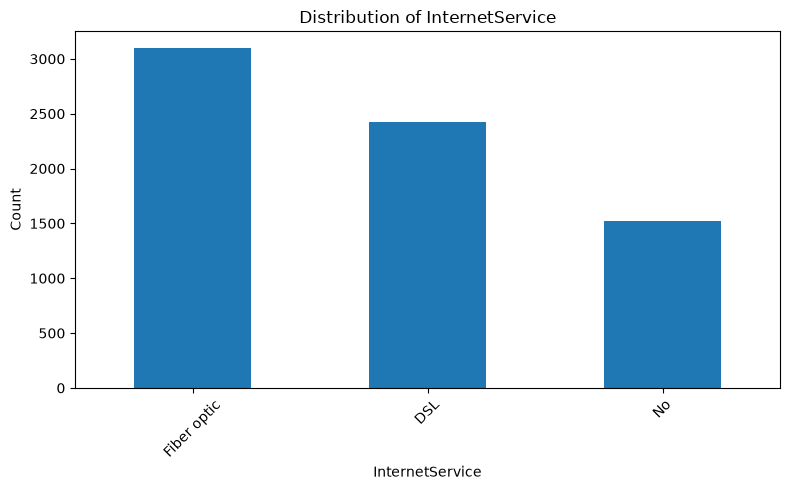

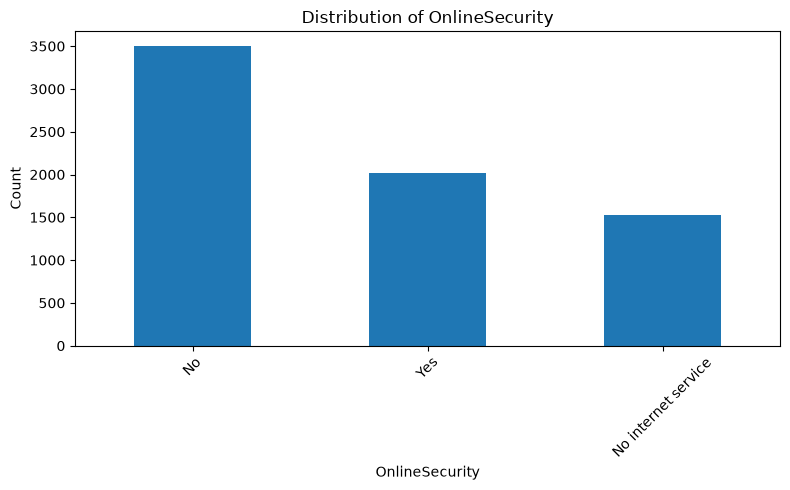

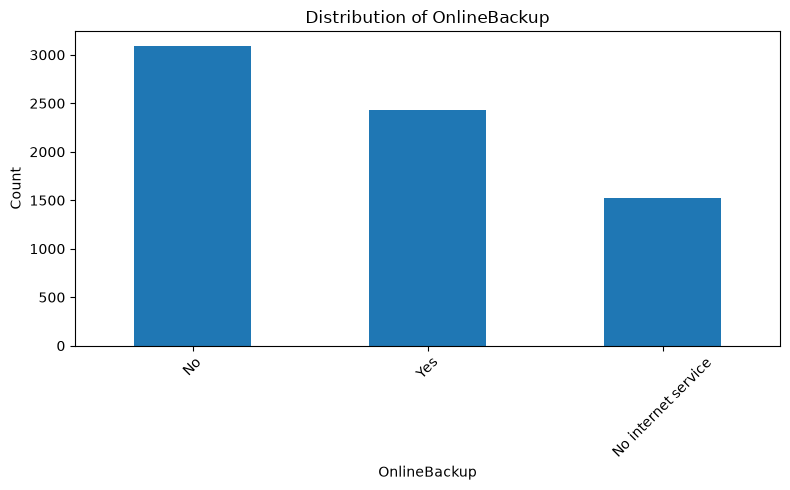

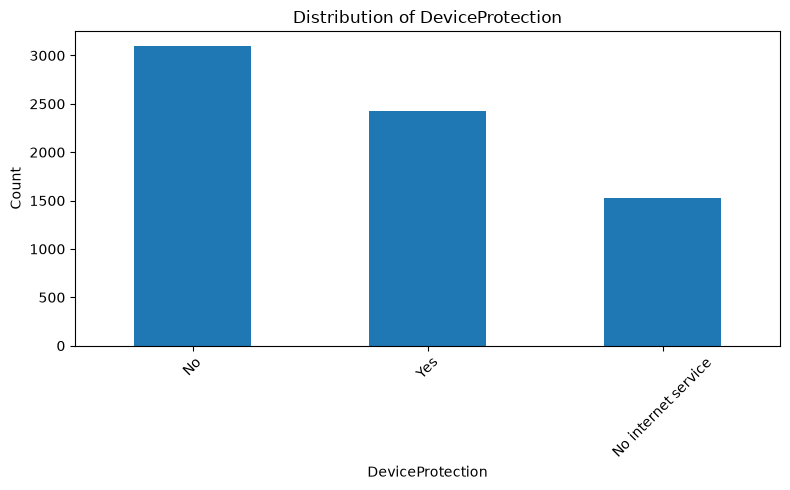

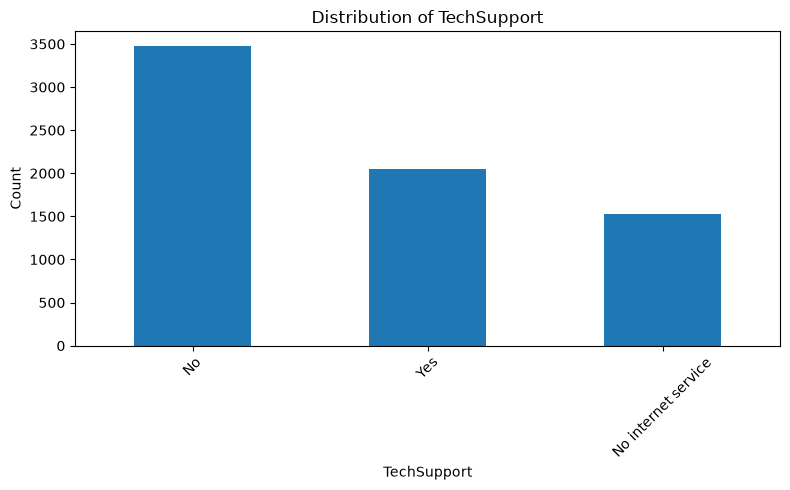

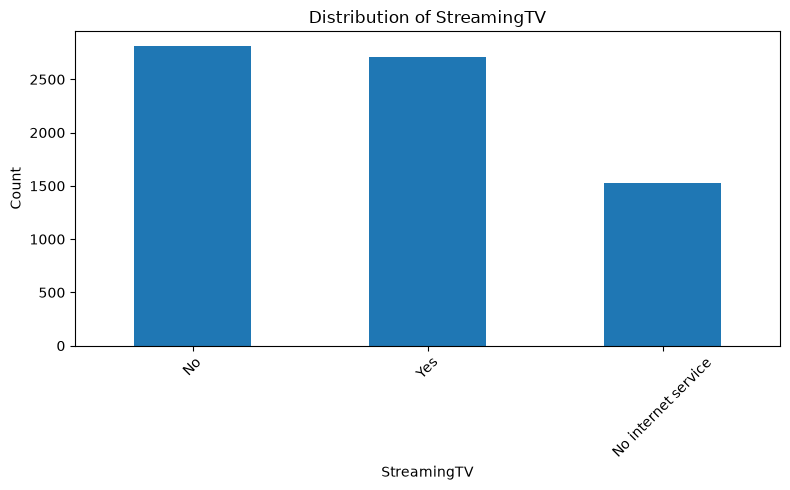

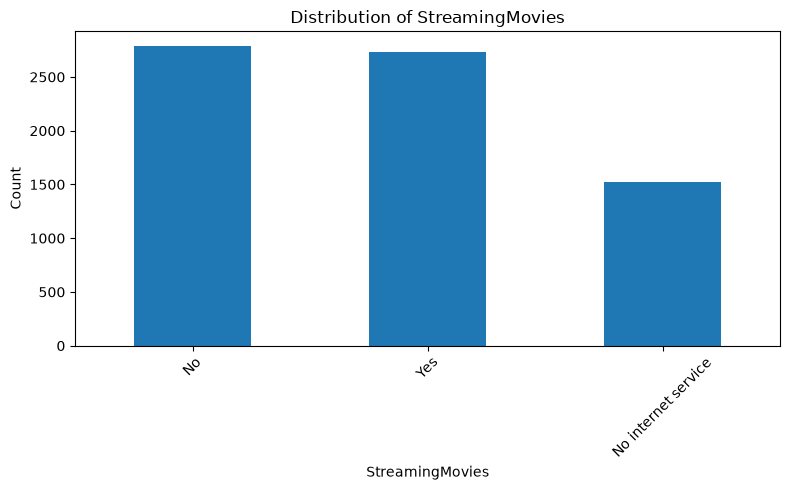

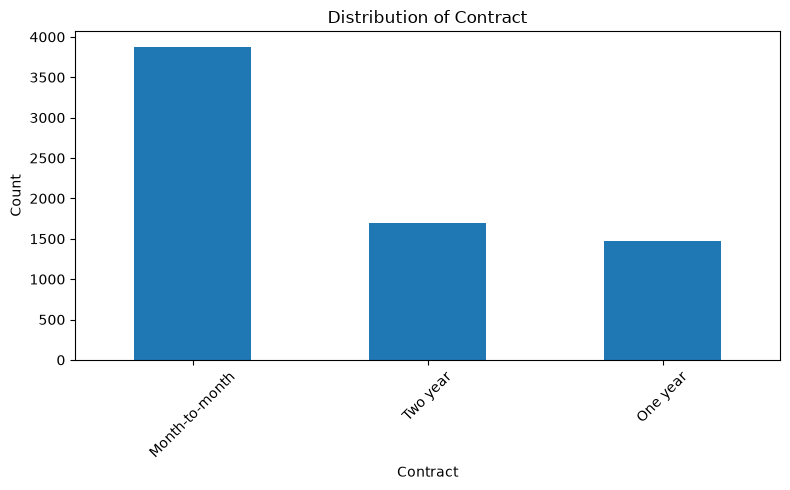

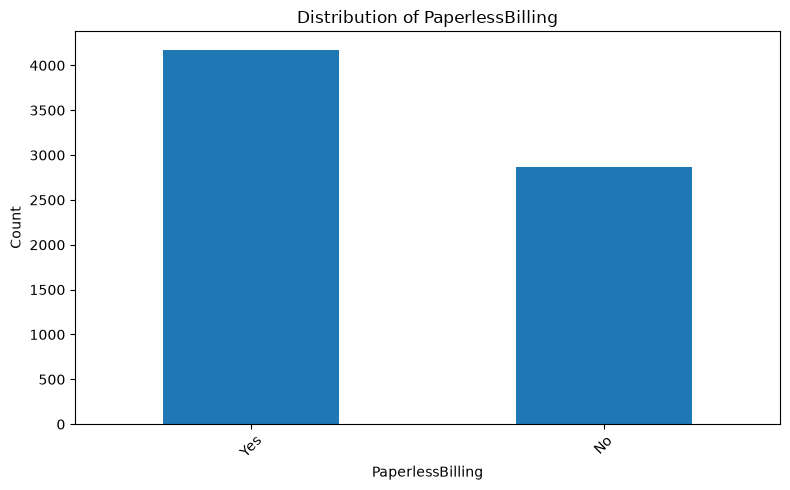

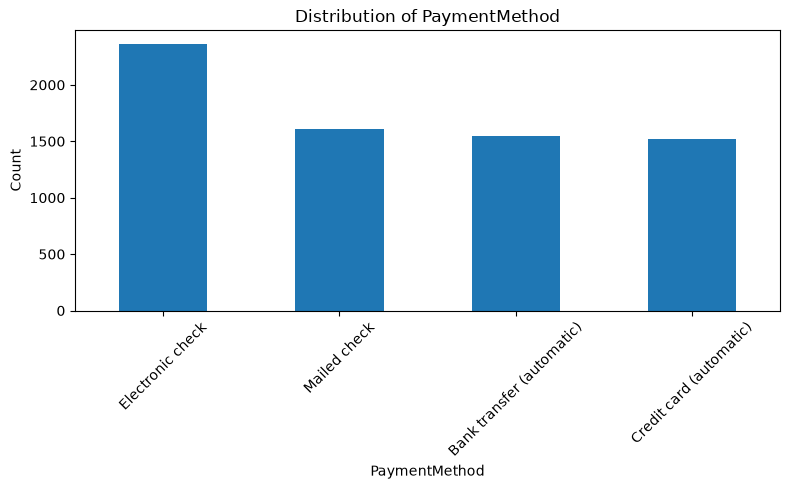

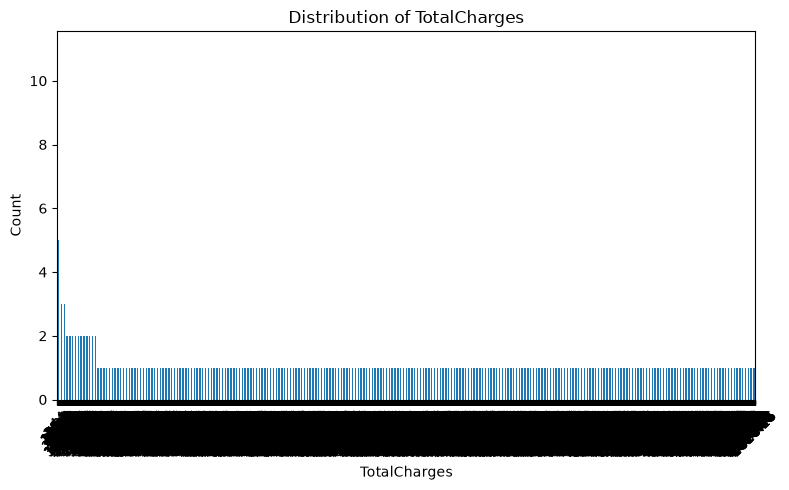

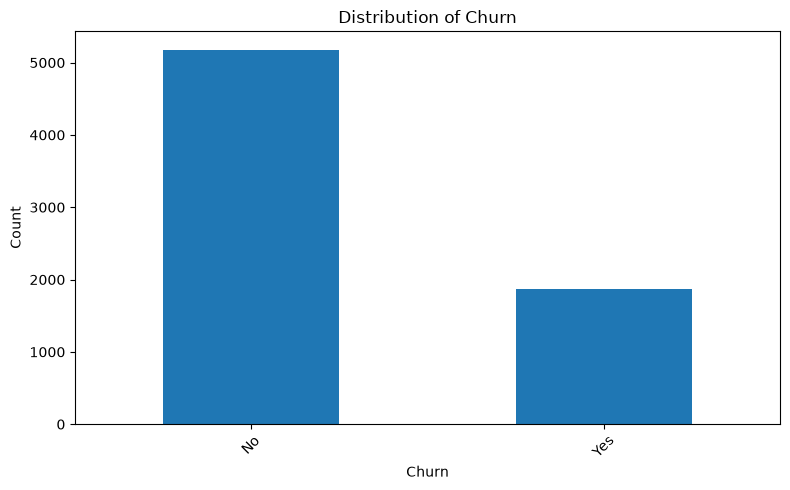

In [13]:
for col in categorical_cols:

    if col != 'customerID':
        plt.figure(figsize=(8, 5))

        df[col].value_counts().plot(kind='bar')

        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Count')

        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [14]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
numerical_cols

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='str')

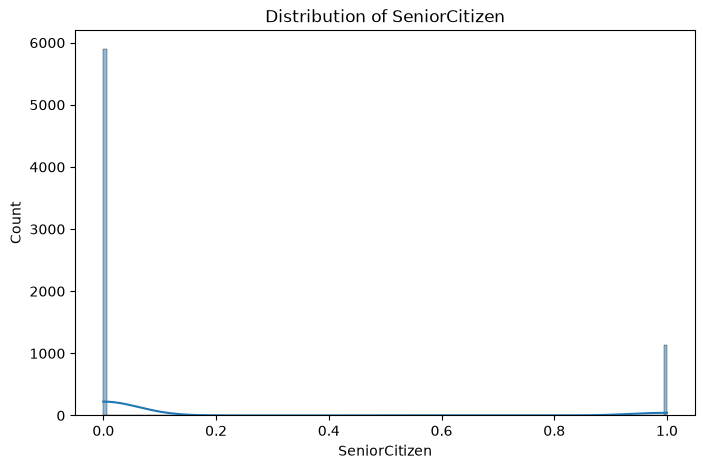

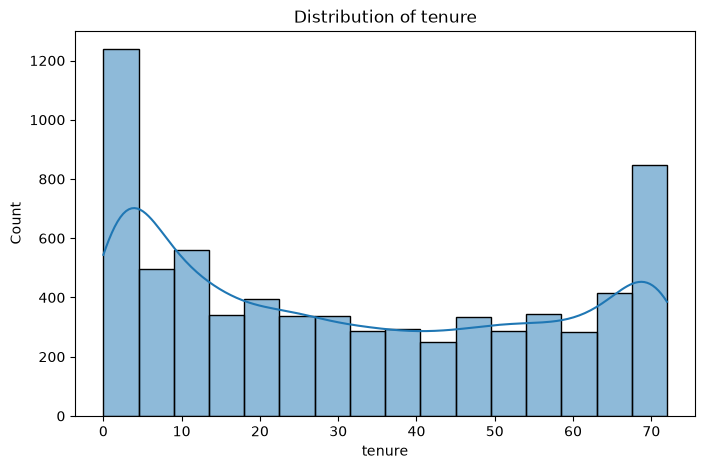

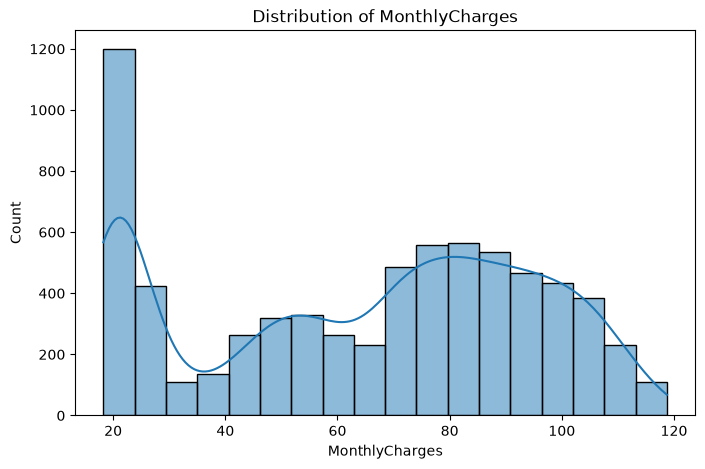

In [15]:
for col in numerical_cols:

    plt.figure(figsize=(8, 5))

    sns.histplot(df[col], kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    plt.show()

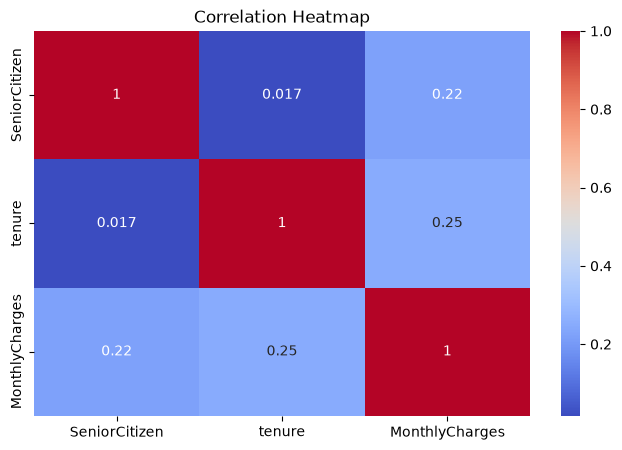

In [16]:
plt.figure(figsize=(8, 5))

sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

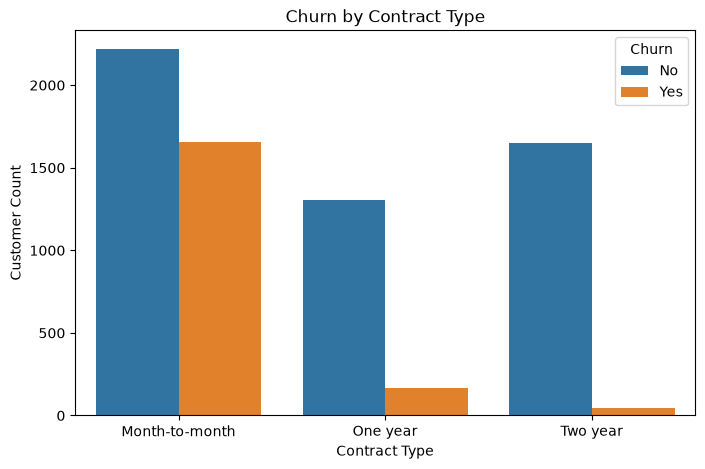

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(x='Contract', hue='Churn', data=df)

plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Customer Count')

plt.show()

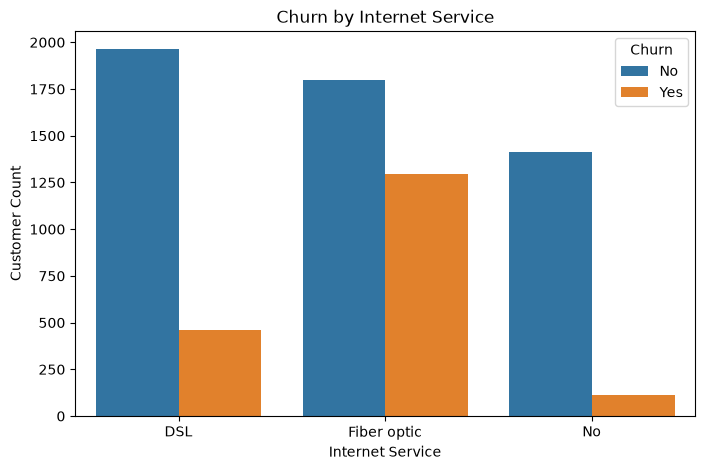

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(x='InternetService', hue='Churn', data=df)

plt.title('Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Customer Count')

plt.show()

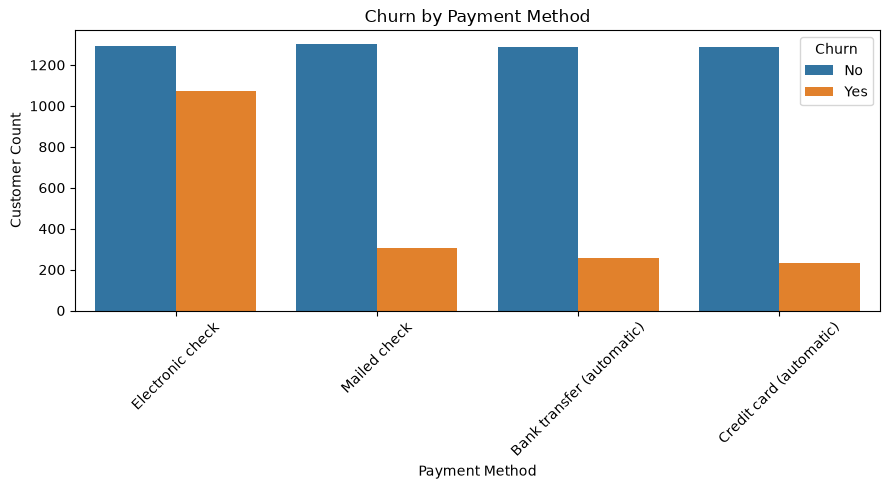

In [19]:
plt.figure(figsize=(9, 5))

sns.countplot(x='PaymentMethod', hue='Churn', data=df)

plt.title('Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Customer Count')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

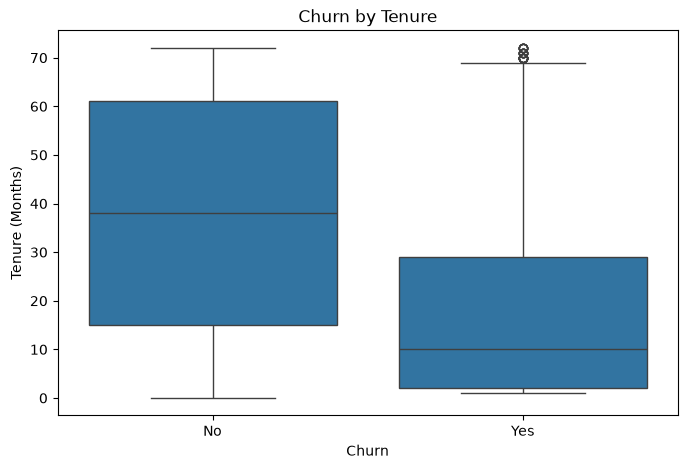

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Churn', y='tenure', data=df)

plt.title('Churn by Tenure')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')

plt.show()

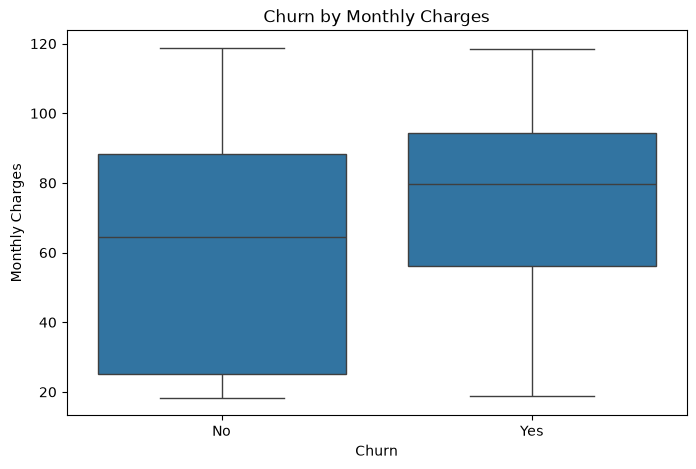

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Churn', y='MonthlyCharges', data=df)

plt.title('Churn by Monthly Charges')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

In [22]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [23]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [24]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [25]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [26]:
df[df['TotalCharges'].isnull()][['tenure', 'TotalCharges']]

,tenure,TotalCharges
488,0,NaN
753,0,NaN
936,0,NaN
1082,0,NaN
1340,0,NaN
3331,0,NaN
3826,0,NaN
4380,0,NaN
5218,0,NaN
6670,0,NaN


In [27]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [28]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.drop('customerID', axis=1, inplace=True)

In [31]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [32]:
df.shape

(7043, 20)

In [33]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [34]:
X = pd.get_dummies(X, drop_first=True)

In [35]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [37]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [39]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [40]:
y_pred = model.predict(X_test)

In [41]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 80.69552874378992 %


In [42]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



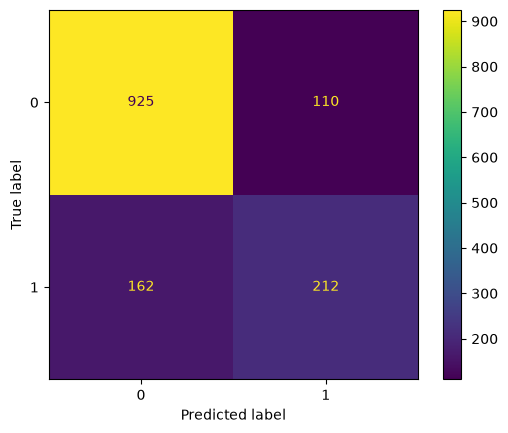

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.show()

In [44]:
import pickle

with open('churn_model.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [45]:
with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file)

print("Scaler saved successfully!")

Scaler saved successfully!


In [46]:
with open('feature_columns.pkl', 'wb') as file:
    pickle.dump(X.columns.tolist(), file)

print("Feature columns saved successfully!")

Feature columns saved successfully!


In [47]:
!pip install gradio

You should consider upgrading via the 'python -m pip install --upgrade pip' command.


In [48]:
import gradio as gr
import pandas as pd
import pickle

# Load trained model
with open('churn_model.pkl', 'rb') as file:
    model = pickle.load(file)

# Load scaler
with open('scaler.pkl', 'rb') as file:
    scaler = pickle.load(file)

# Load feature columns
with open('feature_columns.pkl', 'rb') as file:
    feature_columns = pickle.load(file)


def predict_churn(
    gender, senior, partner, dependents, tenure,
    phone, multiple, internet, security, backup,
    device, tech, tv, movies, contract,
    paperless, payment, monthly, total
):

    input_data = {
        'gender': gender,
        'SeniorCitizen': senior,
        'Partner': partner,
        'Dependents': dependents,
        'tenure': tenure,
        'PhoneService': phone,
        'MultipleLines': multiple,
        'InternetService': internet,
        'OnlineSecurity': security,
        'OnlineBackup': backup,
        'DeviceProtection': device,
        'TechSupport': tech,
        'StreamingTV': tv,
        'StreamingMovies': movies,
        'Contract': contract,
        'PaperlessBilling': paperless,
        'PaymentMethod': payment,
        'MonthlyCharges': monthly,
        'TotalCharges': total
    }

    input_df = pd.DataFrame([input_data])

    input_encoded = pd.get_dummies(input_df)

    input_encoded = input_encoded.reindex(
        columns=feature_columns,
        fill_value=0
    )

    input_scaled = scaler.transform(input_encoded)

    prediction = model.predict(input_scaled)

    if prediction[0] == 1:
        return "Customer is likely to CHURN!"
    else:
        return "Customer is likely to STAY!"


demo = gr.Interface(
    fn=predict_churn,

    inputs=[
        gr.Dropdown(["Male", "Female"], label="Gender"),
        gr.Dropdown([0, 1], label="Senior Citizen"),
        gr.Dropdown(["Yes", "No"], label="Partner"),
        gr.Dropdown(["Yes", "No"], label="Dependents"),
        gr.Number(label="Tenure (Months)", value=12),
        gr.Dropdown(["Yes", "No"], label="Phone Service"),
        gr.Dropdown(["Yes", "No", "No phone service"], label="Multiple Lines"),
        gr.Dropdown(["DSL", "Fiber optic", "No"], label="Internet Service"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Online Security"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Online Backup"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Device Protection"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Tech Support"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Streaming TV"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Streaming Movies"),
        gr.Dropdown(["Month-to-month", "One year", "Two year"], label="Contract"),
        gr.Dropdown(["Yes", "No"], label="Paperless Billing"),
        gr.Dropdown([
            "Electronic check",
            "Mailed check",
            "Bank transfer (automatic)",
            "Credit card (automatic)"
        ], label="Payment Method"),
        gr.Number(label="Monthly Charges", value=70),
        gr.Number(label="Total Charges", value=840)
    ],

    outputs=gr.Textbox(label="Churn Prediction"),
    title="Customer Churn Prediction",
    description="Predict whether a customer will leave the company using Machine Learning."
)

demo.launch(inline=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [49]:
import os

print(os.path.abspath("Untitled.ipynb"))

c:\Users\Admin\Downloads\archive (2)\Untitled.ipynb


In [50]:
import nbformat

path = r"C:\Users\Admin\Downloads\archive (2)\Untitled.ipynb"

nb = nbformat.read(path, as_version=4)

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code" and cell.outputs:
        print("Cell", i, "has", len(cell.outputs), "outputs")

Cell 1 has 1 outputs
Cell 2 has 1 outputs
Cell 3 has 1 outputs
Cell 4 has 1 outputs
Cell 5 has 1 outputs
Cell 6 has 1 outputs
Cell 7 has 1 outputs
Cell 8 has 1 outputs
Cell 9 has 1 outputs
Cell 10 has 1 outputs
Cell 11 has 2 outputs
Cell 12 has 17 outputs
Cell 13 has 1 outputs
Cell 14 has 3 outputs
Cell 15 has 1 outputs
Cell 16 has 1 outputs
Cell 17 has 1 outputs
Cell 18 has 1 outputs
Cell 19 has 1 outputs
Cell 20 has 1 outputs
Cell 21 has 1 outputs
Cell 23 has 1 outputs
Cell 24 has 1 outputs
Cell 25 has 1 outputs
Cell 27 has 1 outputs
Cell 28 has 1 outputs
Cell 30 has 1 outputs
Cell 31 has 1 outputs
Cell 36 has 1 outputs
Cell 38 has 1 outputs
Cell 40 has 1 outputs
Cell 41 has 1 outputs
Cell 42 has 1 outputs
Cell 43 has 1 outputs
Cell 44 has 1 outputs
Cell 45 has 1 outputs
Cell 46 has 2 outputs
Cell 47 has 3 outputs
